#PREPARAÇÃO DO AMBIENTE

In [1]:
# from google.colab import drive
# drive.mount('/gdrive')
# %cd <pasta com os dados no seu Drive>

Mounted at /gdrive
/gdrive/MyDrive/faculdade/8 semestre/INTELIGÊNCIA COMPUTACIONAL/PRATICAS/PRATICA 3


In [10]:
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate
import numpy as np

#PREPARAÇÃO DOS DADOS

In [11]:
#CARREGAR OS DADOS DA COMPETIÇÃO
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

#REDUÇÃO DA BASE DE DADOS PARA VELOCIDADE DE EXECUÇÃO
df_train = df_train.sample(frac=0.20, random_state=42)

# SEPARAR O QUE SERÁ USADO PARA MODELAR (X) E O QUE SERÁ "PREVISTO" (Y)
X = df_train.drop(columns=["ID_code", "target"])
y = df_train["target"]

# DIVISÃO AUTOMÁTICA DE TREINO E TESTE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# DEFINIÇÃO DOS MODELOS
models = {
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, eval_metric='logloss', random_state=42, n_jobs=-1)
}

#AVALIAÇÃO HOLDOUT (TREINO/TESTE)

In [16]:
results = []

for name, model in models.items():
    print(f"Rodando {name}...")

    # treino
    model.fit(X_train, y_train)

    # probabilidade (ESSENCIAL)
    y_probs = model.predict_proba(X_test)[:, 1]

    # AUC ROC
    auc = roc_auc_score(y_test, y_probs)

    results.append({
        "Modelo": name,
        "AUC Holdout": auc
    })


Rodando Naive Bayes...
Rodando Random Forest...
Rodando XGBoost...


In [15]:
# VALIDAÇÃO CRUZADA
for i, (name, model) in enumerate(models.items()):

    cv = cross_validate(
        model,
        X,
        y,
        cv=10,
        scoring='roc_auc',
        n_jobs=-1
    )

    auc_cv = np.mean(cv['test_score'])

    results[i]["AUC CV (10-fold)"] = auc_cv

    df_results = pd.DataFrame(results)
display(df_results)

,Modelo,AUC Holdout,AUC CV (10-fold)
0,Naive Bayes,0.888162,0.885846
1,Random Forest,0.783105,0.777345
2,XGBoost,0.831800,0.829385


#PREPARAÇÃO PARA O KAGGLE

In [17]:
# REMOVER O IDENTIFICADOR
X_kaggle = df_test.drop(columns=["ID_code"])

# modelo CV (XGBoost)
model_cv = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, eval_metric='logloss', random_state=42)
model_cv.fit(X, y)

preds_cv = model_cv.predict_proba(X_kaggle)[:, 1]

In [18]:
# SALVAR MODELO XGBOOST
sub_cv = pd.DataFrame({
    "ID_code": df_test["ID_code"],
    "target": preds_cv
})

sub_cv.to_csv("submission_xgboost.csv", index=False)

In [19]:
# MODELO HOLDOUT (TREINO/TESTE)
model_holdout = GaussianNB()
model_holdout.fit(X, y)

preds_holdout = model_holdout.predict_proba(X_kaggle)[:, 1]

In [20]:
# SALVAR NB HOLDOUT
sub_holdout = pd.DataFrame({
    "ID_code": df_test["ID_code"],
    "target": preds_holdout
})

sub_holdout.to_csv("submission_nb.csv", index=False)

In [21]:
from google.colab import files

files.download("submission_xgboost.csv")
files.download("submission_nb.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

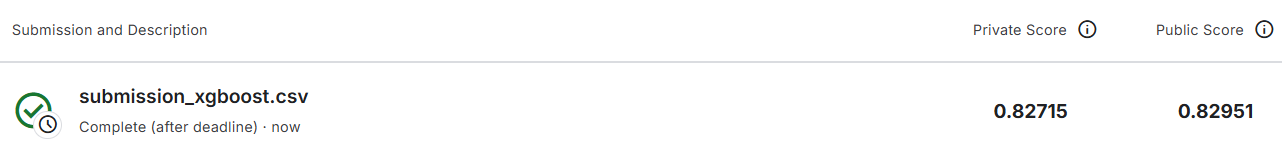

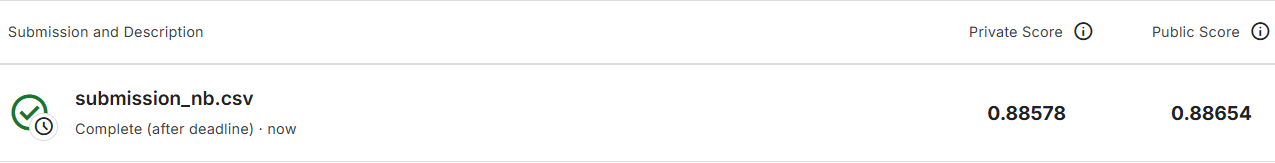

##REFAZENDO O XG BOOST
Como os resultados obtidos foram inferiores ao naive bayes, irei alterar hyperparâmetros para tentar melhorar o resultado

In [23]:
# XGBOOST OTIMIZADO (ajuste de hiperparâmetros)

from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_validate
import numpy as np

model_xgb_opt = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

#  HOLDOUT (train/test)

model_xgb_opt.fit(X_train, y_train)

y_probs = model_xgb_opt.predict_proba(X_test)[:, 1]
auc_holdout = roc_auc_score(y_test, y_probs)

print(f"AUC Holdout (XGBoost Otimizado): {auc_holdout:.4f}")

#  VALIDAÇÃO CRUZADA

cv = cross_validate(
    model_xgb_opt,
    X,
    y,
    cv=10,
    scoring='roc_auc',
    n_jobs=-1
)

auc_cv = np.mean(cv['test_score'])

print(f"AUC Cross-Validation (XGBoost Otimizado): {auc_cv:.4f}")

# TREINO FINAL (KAGGLE)
model_xgb_opt.fit(X, y)

X_kaggle = df_test.drop(columns=["ID_code"])
preds_xgb_opt = model_xgb_opt.predict_proba(X_kaggle)[:, 1]

sub_xgb_opt = pd.DataFrame({
    "ID_code": df_test["ID_code"],
    "target": preds_xgb_opt
})

sub_xgb_opt.to_csv("submission_xgboost_otimizado.csv", index=False)

from google.colab import files
files.download("submission_xgboost_otimizado.csv")

AUC Holdout (XGBoost Otimizado): 0.8623
AUC Cross-Validation (XGBoost Otimizado): 0.8627


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

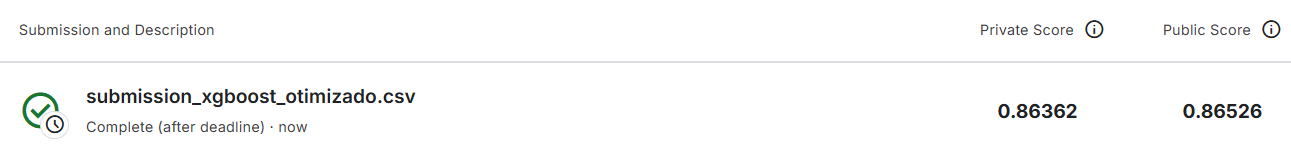

#CONCLUSÃO

O modelo Naive Bayes apresentou melhor desempenho no Kaggle em comparação ao XGBoost na configuração inicial, o que indica que o XGBoost estava com baixa capacidade de aprendizado (underfitting), devido ao uso de poucos estimadores e baixa profundidade. Observou-se que a validação cruzada fornece uma estimativa mais estável em relação ao método holdout, reduzindo a variabilidade dos resultados, embora com maior custo computacional. A diferença entre os resultados locais e do Kaggle pode ser explicada pela divisão dos dados (public e private score) e pelo uso de uma amostra reduzida do conjunto de treino, o que limita a capacidade de generalização dos modelos. Para melhorar os resultados, foi realizada uma nova configuração do XGBoost com aumento do número de árvores, maior profundidade e ajuste da taxa de aprendizado, além do uso de técnicas de regularização como subsample e colsample_bytree, com o objetivo de aumentar a capacidade de aprendizado do modelo e reduzir overfitting, buscando melhor desempenho no leaderboard. Dessa forma, como demonstrado na tabela abaixo, os números gerados nos leva a conclusão de que a baixa quantidade de dados utilizados interferiram diretamente na capacidade do XGBOOST (que por muitas vezes é o melhor modelo), enquanto o Naive Bayes não sofreu tanto com a redução da carga de dados. Mesmo após melhorado, o XGBOOST continuou pior que o NB.

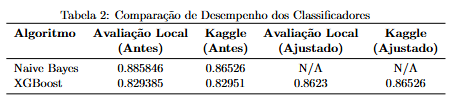